# Teaching an AI about police and public interactions

**The question:** using only what is known when a police stop begins, how likely is it to end in an arrest?

**The data:** [Seattle Terry Stops](https://data.seattle.gov/Public-Safety/Terry-Stops/28ny-9ts8), a public domain
record of real stops of people by Seattle police officers.

**The steps:**
1. Load the data
2. Check it for traps
3. Clean it
4. Split it by time, so the final exam covers stops the AI has never seen
5. Teach several models and pick the best
6. Take the final exam
7. See what the AI learned
8. Check fairness
9. Save the AI
10. Run the AI on example stops

**Please read before using it:** this is a learning project. The AI learns what Seattle officers *decided*, not
whether anyone was guilty, so it must not be used to make decisions about real people.

## Step 1: Load the data

In [1]:
# Tools for reading files and handling tables of data.
import hashlib
import json
import urllib.request
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Tools for teaching and marking the AI.
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Where the data comes from and where our files are kept.
DATASET_URL = "https://data.seattle.gov/api/views/28ny-9ts8/rows.csv?accessType=DOWNLOAD"
RAW_DATA_PATH = Path("data/raw/terry_stops.csv")
MODEL_PATH = Path("models/arrest_outcome_model.joblib")
MODEL_DETAILS_PATH = Path("models/arrest_outcome_model_details.json")
CHARTS_FOLDER = Path("charts")

# The years used to teach, to choose the best model, and for the final exam.
LAST_TRAINING_YEAR = 2023
CHOOSING_YEAR = 2024
FIRST_EXAM_YEAR = 2025
FIRST_RELIABLE_YEAR = 2015

# The dataset writes "-" when a value is blank.
BLANK_MARKER = "-"

# Fixing the random seed means every run gives the same results.
RANDOM_SEED = 42

# Rare values with fewer rows than this are grouped into one "rare" bucket.
MINIMUM_ROWS_FOR_A_CATEGORY = 20

# How many times the exam is re-marked to measure how far the score could move by chance.
BOOTSTRAP_ROUNDS = 500

# Fairness results are only shown for groups with at least this many exam stops.
MINIMUM_GROUP_SIZE = 100

# Chart colours and shared chart settings.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.edgecolor": "#c9c8c2", "text.color": "#0b0b0b",
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
                     "grid.color": "#ecebe7", "axes.axisbelow": True, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titleweight": "bold"})
CHARTS_FOLDER.mkdir(exist_ok=True)
MODEL_PATH.parent.mkdir(exist_ok=True)


def download_dataset_if_missing():
    """Download the CSV the first time only, so later runs use exactly the same data."""
    if RAW_DATA_PATH.exists():
        return
    RAW_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATASET_URL, RAW_DATA_PATH)


def fingerprint_of_file(path):
    """Return a short code that changes if even one byte of the file changes."""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:16]


def save_chart(figure, file_name):
    """Tidy the chart's spacing and save a copy in the charts folder."""
    figure.tight_layout()
    figure.savefig(CHARTS_FOLDER / file_name, bbox_inches="tight")


# Get the data, then read every row into a table.
download_dataset_if_missing()
raw_stops = pd.read_csv(RAW_DATA_PATH, low_memory=False)
data_fingerprint = fingerprint_of_file(RAW_DATA_PATH)
print(f"{len(raw_stops):,} rows and {raw_stops.shape[1]} columns. Data fingerprint: {data_fingerprint}")
print("Columns:", ", ".join(raw_stops.columns))

69,663 rows and 23 columns. Data fingerprint: c26c1a02da69277c
Columns: Subject Age Group, Subject ID, GO / SC Num, Terry Stop ID, Stop Resolution, Weapon Type, Officer ID, Officer YOB, Officer Gender, Officer Race, Subject Perceived Race, Subject Perceived Gender, Reported Date, Initial Call Type, Final Call Type, Call Type, Officer Squad, Arrest Flag, Frisk Flag, Precinct, Sector, Beat, Occurred Date


## Step 2: Check the data for traps

An AI believes whatever it is shown. If the data contains a hidden hint or a mistake, the AI gets a great score but
learns nothing useful, so we check first.

**Trap 1: two columns record arrests, and they disagree.** Which one is the right answer to teach?

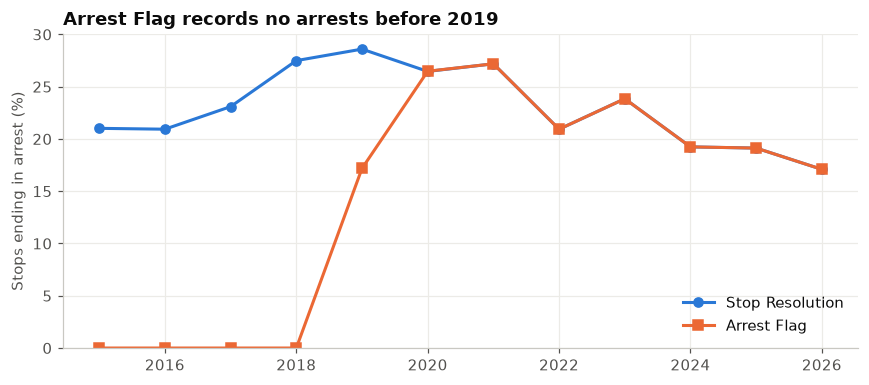

,Stop Resolution,Arrest Flag
Occurred Date,,
2015,21.0,0.0
2016,20.9,0.0
2017,23.1,0.0
2018,27.5,0.0
2019,28.6,17.2
2020,26.5,26.5
2021,27.2,27.2
2022,20.9,20.9
2023,23.8,23.8


In [2]:
# Work out the year of each stop. The first four characters of the date are the year.
stop_years = raw_stops["Occurred Date"].str[:4].astype(int)

# Work out the arrest rate according to each of the two columns, for each year.
arrest_rate_by_year = pd.DataFrame({
    "Stop Resolution": raw_stops["Stop Resolution"].eq("Arrest").groupby(stop_years).mean(),
    "Arrest Flag": raw_stops["Arrest Flag"].eq("Y").groupby(stop_years).mean(),
}).loc[FIRST_RELIABLE_YEAR:]

# Draw both columns as lines, so the disagreement is easy to see.
figure, axis = plt.subplots(figsize=(8, 3.6))
for column, colour, marker in [("Stop Resolution", BLUE, "o"), ("Arrest Flag", ORANGE, "s")]:
    axis.plot(arrest_rate_by_year.index, arrest_rate_by_year[column] * 100, color=colour, linewidth=2,
              marker=marker, markersize=6, label=column)
axis.set_title("Arrest Flag records no arrests before 2019")
axis.set_ylabel("Stops ending in arrest (%)")
axis.set_ylim(bottom=0)
axis.legend(frameon=False, loc="lower right")
save_chart(figure, "01_arrest_columns_by_year.png")
plt.show()
(arrest_rate_by_year * 100).round(1)

`Arrest Flag` was clearly not filled in before 2019, so **`Stop Resolution` is the answer we teach**.

**Trap 2: blank records that give away the answer.** Blank call and precinct details mostly belong to older records.
If those stops also end in arrest far less often, the AI could learn that "blank means no arrest". That is a fact about
record keeping, not about the stop.

In [3]:
# Mark the rows with a blank call type or a blank precinct.
is_arrest = raw_stops["Stop Resolution"].eq("Arrest")
has_blank_call_details = raw_stops["Call Type"].eq(BLANK_MARKER) | raw_stops["Precinct"].eq(BLANK_MARKER)

# Compare how often those rows end in arrest, and how the blanks change over time.
print("Arrest rate when the details are present:", f"{is_arrest[~has_blank_call_details].mean():.1%}")
print("Arrest rate when the details are blank:  ", f"{is_arrest[has_blank_call_details].mean():.1%}")
print()
print("Share of rows with blank details, by year:")
print((has_blank_call_details.groupby(stop_years).mean().loc[FIRST_RELIABLE_YEAR:] * 100).round(1).to_string())

Arrest rate when the details are present: 28.1%
Arrest rate when the details are blank:   8.3%

Share of rows with blank details, by year:
Occurred Date
2015    40.7
2016    39.9
2017    36.8
2018    33.1
2019    21.6
2020     8.7
2021    10.0
2022     9.1
2023     7.6
2024     7.6
2025     8.2
2026     7.5


The gap is large, so **we remove those rows**. As a result, the AI can only speak about stops that have call details.

**Trap 3: columns that give away the answer.** The AI may only see what is known when a stop *begins*.

| Columns | What we do | Why |
|---|---|---|
| `Weapon Type`, `Frisk Flag`, `Final Call Type` | Not used | Only known during or after the stop |
| `Arrest Flag`, `Stop Resolution` | Not used as inputs | These are the answer |
| `Subject ID`, `GO / SC Num`, `Terry Stop ID` | Not used | Record numbers, not facts about the stop |
| `Reported Date` | Not used | Filled in after the stop |
| `Officer ID`, `Officer YOB`, `Officer Gender`, `Officer Race`, `Officer Squad` | Not used | We don't want the AI judging stops by which officer made them |
| `Subject Perceived Race`, `Subject Perceived Gender`, `Subject Age Group` | Not used | Used only in Step 8, to check fairness |
| `Call Type`, `Initial Call Type`, `Precinct`, `Sector`, `Beat`, time of day, weekday, month | **Used** | Known when the stop begins |

## Step 3: Clean the data

In [4]:
# The only details the AI is allowed to see.
CALL_FEATURES = ["call_type", "initial_call_type"]
PLACE_FEATURES = ["precinct", "sector", "beat"]
TIME_FEATURES = ["hour_of_day", "day_of_week", "month"]
ALL_FEATURES = CALL_FEATURES + PLACE_FEATURES + TIME_FEATURES

# Columns that must never reach the AI. A check further down enforces this.
FORBIDDEN_FEATURES = {"Weapon Type", "Frisk Flag", "Final Call Type", "Arrest Flag", "Stop Resolution", "Subject ID",
                      "GO / SC Num", "Terry Stop ID", "Reported Date", "Officer ID", "Officer YOB", "Officer Gender",
                      "Officer Race", "Officer Squad", "Subject Perceived Race", "Subject Perceived Gender",
                      "Subject Age Group"}


def add_time_features(stops, occurred_at):
    """Turn a date and time into the hour, weekday and month, stored as text labels."""
    return stops.assign(hour_of_day=occurred_at.dt.hour.astype(str), day_of_week=occurred_at.dt.day_name(),
                        month=occurred_at.dt.month_name())


def remove_unusable_rows(stops):
    """Remove repeated stops, stops before 2015, and stops with blank call or precinct details."""
    # A stop with two weapons is listed twice. Keep one row per stop.
    unique_stops = stops.drop_duplicates("Terry Stop ID")
    is_recent_enough = unique_stops["Occurred Date"].str[:4].astype(int) >= FIRST_RELIABLE_YEAR
    has_call_details = (unique_stops["Call Type"].ne(BLANK_MARKER) & unique_stops["Initial Call Type"].ne(BLANK_MARKER)
                        & unique_stops["Precinct"].ne(BLANK_MARKER))
    return unique_stops[is_recent_enough & has_call_details]


def build_clean_stops(stops):
    """Create the tidy table: the AI's inputs, the answer, and the columns needed for checks."""
    usable_stops = remove_unusable_rows(stops)
    # The file labels times as UTC, but its daily pattern looks like local time, so the times are not converted.
    occurred_at = pd.to_datetime(usable_stops["Occurred Date"].str.replace("Z", "", regex=False))
    clean_stops = pd.DataFrame({
        "call_type": usable_stops["Call Type"],
        "initial_call_type": usable_stops["Initial Call Type"],
        "precinct": usable_stops["Precinct"],
        "sector": usable_stops["Sector"],
        "beat": usable_stops["Beat"],
        "ended_in_arrest": usable_stops["Stop Resolution"].eq("Arrest").astype(int),
        "year": occurred_at.dt.year,
        "incident_number": usable_stops["GO / SC Num"],
        "perceived_race": usable_stops["Subject Perceived Race"],
    })
    return add_time_features(clean_stops, occurred_at).reset_index(drop=True)


# Clean the data and report how many rows are left.
stops = build_clean_stops(raw_stops)
print(f"Kept {len(stops):,} of {len(raw_stops):,} rows. {stops['ended_in_arrest'].mean():.1%} ended in arrest.")
stops[ALL_FEATURES + ["ended_in_arrest"]].head()

Kept 53,596 of 69,663 rows. 28.0% ended in arrest.


,call_type,initial_call_type,precinct,sector,beat,hour_of_day,day_of_week,month,ended_in_arrest
0,911,ASLT - WITH OR W/O WPNS (NO SHOOTINGS),West,M,M3,13,Friday,February,1
1,ONVIEW,"NARCOTICS - VIOLATIONS (LOITER, USE, SELL, NARS)",West,K,K3,12,Saturday,October,0
2,911,OBS - FIGHT - IP - PHYSICAL (NO WEAPONS),North,L,L3,3,Sunday,August,1
3,ONVIEW,DISTURBANCE,West,M,M2,8,Saturday,February,0
4,911,ASLT - CRITICAL (NO SHOOTINGS),North,B,B3,16,Monday,October,0


## Step 4: Split the data by time

A normal random split would let the AI study 2026 stops and then be tested on other 2026 stops. Real use is harder,
because the AI has to predict a future it hasn't seen. So we split like this:

| Part | Years | Job |
|---|---|---|
| Teaching | 2015-2023 | The AI learns from these |
| Choosing | 2024 | Picks the best model, corrects its percentages and sets the alert level |
| Final exam | 2025-2026 | Used at the end, for the real score |

One incident can involve several people, so all of an incident's stops must stay on the same side of the split.

In [5]:
def remove_incidents_seen_later(earlier_stops, later_stops):
    """Drop earlier rows whose incident also appears later, so no incident is on both sides."""
    return earlier_stops[~earlier_stops["incident_number"].isin(later_stops["incident_number"])]


# Cut the table into its three parts, by year.
exam_stops = stops[stops["year"] >= FIRST_EXAM_YEAR]
choosing_stops = remove_incidents_seen_later(stops[stops["year"] == CHOOSING_YEAR], exam_stops)
later_stops = pd.concat([choosing_stops, exam_stops])
teaching_stops = remove_incidents_seen_later(stops[stops["year"] <= LAST_TRAINING_YEAR], later_stops)

# Safety checks: the notebook stops with an error if any of these rules is broken.
assert not FORBIDDEN_FEATURES & set(ALL_FEATURES), "A forbidden column reached the AI"
assert teaching_stops["year"].max() < choosing_stops["year"].min() <= choosing_stops["year"].max() < exam_stops["year"].min()
assert not set(teaching_stops["incident_number"]) & set(later_stops["incident_number"]), "Incident on both sides"
assert not set(choosing_stops["incident_number"]) & set(exam_stops["incident_number"]), "Incident on both sides"

# Show the size of each part and how often its stops ended in arrest.
pd.DataFrame({
    "stops": [len(part) for part in (teaching_stops, choosing_stops, exam_stops)],
    "arrest rate %": [round(part["ended_in_arrest"].mean() * 100, 1) for part in (teaching_stops, choosing_stops, exam_stops)],
}, index=["Teaching 2015-2023", "Choosing 2024", "Final exam 2025-2026"])

,stops,arrest rate %
Teaching 2015-2023,43239,30.4
Choosing 2024,3468,18.5
Final exam 2025-2026,6889,18.2


Notice that arrests are **much less common** in 2024 and later than in the teaching years. The world changed, so an AI
taught on the older years will overestimate arrests. After choosing the model, we correct for this using 2024 only.

## Step 5: Teach several models and pick the best

We start with models simple enough to act as a yardstick. A clever model is only worth keeping if it beats them.

| Model | How it works |
|---|---|
| Always guess the average | No learning at all. Gives every stop the same chance |
| Call type only | Logistic regression that sees only the call details |
| All details, simple | Logistic regression that sees everything allowed |
| All details, advanced | Gradient boosting, many small decision trees that correct each other |

**How the scores work:**
- **AUC:** given one arrest stop and one non-arrest stop, how often does the AI rate the arrest stop higher? 0.50 is a coin toss and 1.00 is perfect.
- **Average precision:** how well the AI ranks arrests at the top of its list. Blind guessing scores about the arrest rate.
- **Brier score:** how far its percentages are from what happened. **Lower is better.**

In [6]:
def build_one_hot_encoder(feature_names):
    """Turn text labels into yes/no number columns, because models can only read numbers."""
    encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MINIMUM_ROWS_FOR_A_CATEGORY,
                            sparse_output=False)
    return ColumnTransformer([("encode_labels", encoder, feature_names)])


def build_logistic_model(feature_names):
    """Build a simple model that gives each detail a score and adds the scores up."""
    return Pipeline([("encode", build_one_hot_encoder(feature_names)),
                     ("learn", LogisticRegression(max_iter=2000, random_state=RANDOM_SEED))])


def build_boosted_model(feature_names):
    """Build an advanced model of many small decision trees, each fixing the last one's mistakes."""
    trees = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31, l2_regularization=1.0,
                                           early_stopping=False, random_state=RANDOM_SEED)
    return Pipeline([("encode", build_one_hot_encoder(feature_names)), ("learn", trees)])


def build_candidate_models():
    """List every model that will compete."""
    return {
        "Always guess the average": DummyClassifier(strategy="prior"),
        "Call type only": build_logistic_model(CALL_FEATURES),
        "All details, simple": build_logistic_model(ALL_FEATURES),
        "All details, advanced": build_boosted_model(ALL_FEATURES),
    }


def arrest_chances(model, stops_to_score):
    """Ask a model for the chance of arrest for each stop, from 0 to 1."""
    return model.predict_proba(stops_to_score[ALL_FEATURES])[:, 1]


def score_chances(actual_outcomes, chances):
    """Mark a set of predictions using the three scores explained above."""
    return {"AUC": roc_auc_score(actual_outcomes, chances),
            "Average precision": average_precision_score(actual_outcomes, chances),
            "Brier (lower is better)": brier_score_loss(actual_outcomes, chances)}


def teach_and_compare(candidates):
    """Teach each model on 2015-2023, then mark it on the 2024 stops it has not seen."""
    results = {}
    for name, model in candidates.items():
        model.fit(teaching_stops[ALL_FEATURES], teaching_stops["ended_in_arrest"])
        results[name] = score_chances(choosing_stops["ended_in_arrest"], arrest_chances(model, choosing_stops))
    return pd.DataFrame(results).T


# Teach every candidate, then pick the one with the best average precision on 2024.
candidates = build_candidate_models()
choosing_scores = teach_and_compare(candidates)
best_model_name = choosing_scores["Average precision"].idxmax()
print("Best model on the 2024 stops:", best_model_name)
choosing_scores.round(3)

Best model on the 2024 stops: All details, simple


,AUC,Average precision,Brier (lower is better)
Always guess the average,0.500,0.185,0.165
Call type only,0.667,0.336,0.149
"All details, simple",0.680,0.344,0.148
"All details, advanced",0.680,0.335,0.149


In [7]:
def find_chance_adjustment(actual_outcomes, chances):
    """Find the shift that makes the average predicted chance match the real arrest rate."""
    def gap_from_real_rate(shift):
        return shift_chances(chances, shift).mean() - actual_outcomes.mean()
    return float(brentq(gap_from_real_rate, -5, 5))


def shift_chances(chances, shift):
    """Move every chance up or down by the same amount, keeping the order of the stops."""
    return expit(logit(chances) + shift)


def choose_alert_level(actual_outcomes, chances):
    """Find the chance above which the AI should say "likely arrest", using the best F1 balance."""
    precision, recall, levels = precision_recall_curve(actual_outcomes, chances)
    f1_scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(levels[f1_scores.argmax()])


def compare_memory_with_new_stops(model):
    """Compare scores on stops the AI studied and stops it has not seen. A big gap means it memorised."""
    studied = score_chances(teaching_stops["ended_in_arrest"], arrest_chances(model, teaching_stops))
    unseen = score_chances(choosing_stops["ended_in_arrest"], arrest_chances(model, choosing_stops))
    return pd.DataFrame({"Studied 2015-2023": studied, "Not seen 2024": unseen})


# Correct the percentages and choose the alert level on 2024, so the final exam plays no part in either.
best_model = candidates[best_model_name]
choosing_chances = arrest_chances(best_model, choosing_stops)
chance_adjustment = find_chance_adjustment(choosing_stops["ended_in_arrest"], choosing_chances)
adjusted_choosing_chances = shift_chances(choosing_chances, chance_adjustment)
alert_level = choose_alert_level(choosing_stops["ended_in_arrest"], adjusted_choosing_chances)
print(f"2024 average chance before correction: {choosing_chances.mean():.1%}. After: {adjusted_choosing_chances.mean():.1%}.")
print(f"The AI says 'likely arrest' when the corrected chance is {alert_level:.1%} or higher.")
compare_memory_with_new_stops(best_model).round(3)

2024 average chance before correction: 27.8%. After: 18.5%.
The AI says 'likely arrest' when the corrected chance is 20.4% or higher.


,Studied 2015-2023,Not seen 2024
AUC,0.655,0.680
Average precision,0.454,0.344
Brier (lower is better),0.197,0.148


## Step 6: The final exam

Everything is now locked: the model, its correction and its alert level. We then mark it on 2025-2026. The yardstick
is a fair one: it gives every stop the real 2024 arrest rate, which is the best guess possible without any AI.

Stops from one incident are linked, so to see how far the score could move by chance we re-mark the exam many times,
drawing whole incidents at random. This gives each score a range.

In [8]:
def draw_random_incident_weights(exam_table):
    """Each round, draw whole incidents at random and say how many times each stop was drawn."""
    random_numbers = np.random.default_rng(RANDOM_SEED)
    incident_codes = pd.factorize(exam_table["incident_number"])[0]
    incident_count = incident_codes.max() + 1
    for _ in range(BOOTSTRAP_ROUNDS):
        times_drawn = np.bincount(random_numbers.integers(incident_count, size=incident_count), minlength=incident_count)
        yield times_drawn[incident_codes]


def bootstrap_score_ranges(exam_table, chances):
    """Re-mark the exam many times using random incidents, and return the middle 95% of each score."""
    actual_outcomes = exam_table["ended_in_arrest"].to_numpy()
    rounds = []
    for row_weights in draw_random_incident_weights(exam_table):
        rounds.append({"AUC": roc_auc_score(actual_outcomes, chances, sample_weight=row_weights),
                       "Average precision": average_precision_score(actual_outcomes, chances, sample_weight=row_weights),
                       "Brier (lower is better)": brier_score_loss(actual_outcomes, chances, sample_weight=row_weights)})
    return pd.DataFrame(rounds).quantile([0.025, 0.975]).T.set_axis(["range low", "range high"], axis=1)


def build_exam_report(actual_scores, score_ranges):
    """Join the actual scores to their ranges in one table."""
    return pd.Series(actual_scores, name="score").to_frame().join(score_ranges)


# Sit the exam, using the corrected chances.
exam_outcomes = exam_stops["ended_in_arrest"]
uncorrected_exam_chances = arrest_chances(best_model, exam_stops)
exam_chances = shift_chances(uncorrected_exam_chances, chance_adjustment)
exam_scores = score_chances(exam_outcomes, exam_chances)

# Mark the yardstick, which gives every stop the real 2024 arrest rate.
yardstick_chances = np.full(len(exam_stops), choosing_stops["ended_in_arrest"].mean())
yardstick_scores = score_chances(exam_outcomes, yardstick_chances)

# Show the results side by side.
exam_report = build_exam_report(exam_scores, bootstrap_score_ranges(exam_stops, exam_chances))
exam_report["yardstick"] = pd.Series(yardstick_scores)
print(f"Final exam: {len(exam_stops):,} stops, {exam_outcomes.mean():.1%} ended in arrest. Model: {best_model_name}")
print(f"Brier without the correction: {brier_score_loss(exam_outcomes, uncorrected_exam_chances):.3f}")
exam_report.round(3)

Final exam: 6,889 stops, 18.2% ended in arrest. Model: All details, simple
Brier without the correction: 0.153


,score,range low,range high,yardstick
AUC,0.637,0.620,0.654,0.500
Average precision,0.296,0.274,0.322,0.182
Brier (lower is better),0.142,0.137,0.148,0.149


In [9]:
def build_results_table(actual_outcomes, chances, level):
    """Count the AI's right and wrong calls at the chosen alert level."""
    said_likely_arrest = chances >= level
    counts = confusion_matrix(actual_outcomes, said_likely_arrest, labels=[0, 1])
    return pd.DataFrame(counts, index=["Actually no arrest", "Actually arrest"], columns=["AI: unlikely", "AI: likely"])


# Show every right and wrong call in the exam.
results_table = build_results_table(exam_outcomes, exam_chances, alert_level)
true_alarms = results_table.loc["Actually arrest", "AI: likely"]
all_alarms = results_table["AI: likely"].sum()
all_arrests = results_table.loc["Actually arrest"].sum()
print(f"When the AI said 'likely arrest', it was right {true_alarms / all_alarms:.1%} of the time.")
print(f"It caught {true_alarms / all_arrests:.1%} of the real arrests.")
results_table

When the AI said 'likely arrest', it was right 28.1% of the time.
It caught 48.9% of the real arrests.


,AI: unlikely,AI: likely
Actually no arrest,4073,1564
Actually arrest,640,612


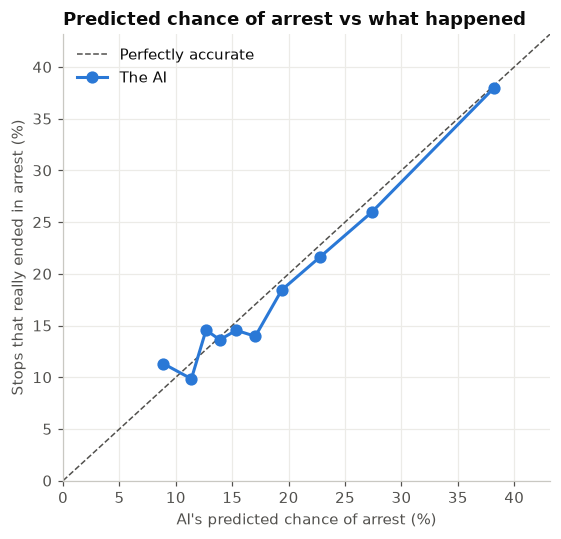

Average predicted chance: 18.7%. Actual arrest rate: 18.2%.


,predicted,actual
predicted,,
"(0.0148, 0.105]",8.9,11.3
"(0.105, 0.121]",11.4,9.8
"(0.121, 0.132]",12.7,14.6
"(0.132, 0.146]",13.9,13.6
"(0.146, 0.161]",15.4,14.5
"(0.161, 0.181]",17.0,14.0
"(0.181, 0.207]",19.4,18.4
"(0.207, 0.249]",22.8,21.6
"(0.249, 0.302]",27.4,25.9


In [10]:
def compare_predicted_with_actual(actual_outcomes, chances, group_count=10):
    """Sort stops into equal groups by predicted chance, then compare with what really happened."""
    table = pd.DataFrame({"predicted": chances, "actual": actual_outcomes.to_numpy()})
    groups = pd.qcut(table["predicted"], group_count, duplicates="drop")
    return table.groupby(groups, observed=True).mean()


# When the AI says 40%, did about 40% of those stops end in arrest?
calibration = compare_predicted_with_actual(exam_outcomes, exam_chances) * 100
largest_percent = calibration.max().max() + 5

# Points on the dashed line mean the AI's percentages were accurate.
figure, axis = plt.subplots(figsize=(5.2, 5))
axis.plot([0, largest_percent], [0, largest_percent], color=INK, linestyle="--", linewidth=1, label="Perfectly accurate")
axis.plot(calibration["predicted"], calibration["actual"], color=BLUE, linewidth=2, marker="o", markersize=7, label="The AI")
axis.set_title("Predicted chance of arrest vs what happened")
axis.set_xlabel("AI's predicted chance of arrest (%)")
axis.set_ylabel("Stops that really ended in arrest (%)")
axis.set_xlim(0, largest_percent)
axis.set_ylim(0, largest_percent)
axis.legend(frameon=False, loc="upper left")
save_chart(figure, "02_predicted_vs_actual.png")
plt.show()
print(f"Average predicted chance: {exam_chances.mean():.1%}. Actual arrest rate: {exam_outcomes.mean():.1%}.")
calibration.round(1)

## Step 7: See what the AI learned

To test how much the AI relies on a detail, we shuffle that column and watch how far the score falls. If it falls a lot,
the AI depended on that detail. We use the 2024 stops and the model taught on 2015-2023, so the exam stays untouched.

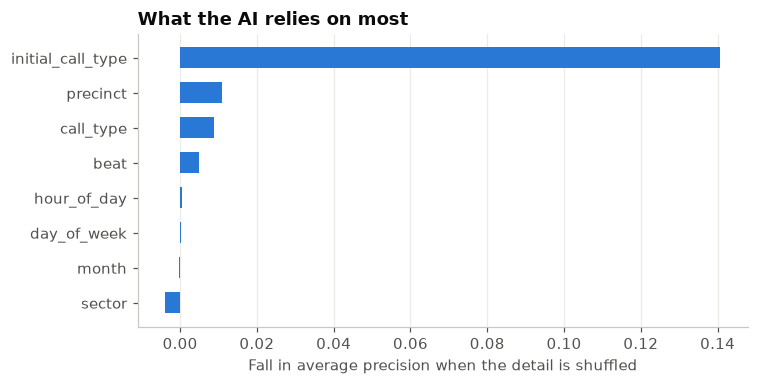

,stops,arrest_rate
initial_call_type,,
WARRANT - MISD PICKUP,204,0.627
WARRANT - FELONY PICKUP,514,0.617
DUI - DRIVING UNDER INFLUENCE,205,0.595
ASLT - DV CRITICAL,889,0.561
OBS - MVC - WITH INJURIES (INCLUDES HIT AND RUN),172,0.547
MVC - HIT AND RUN,174,0.506
HAZ - POTENTIAL THRT TO PHYS SAFETY,190,0.179
PERSON IN BEHAVIORAL/EMOTIONAL CRISIS,223,0.161
BURN - RECKLESS BURNING,193,0.150


In [11]:
def measure_feature_importance(model, stops_to_shuffle):
    """Shuffle one column at a time and record how much the average precision drops."""
    result = permutation_importance(model, stops_to_shuffle[ALL_FEATURES], stops_to_shuffle["ended_in_arrest"],
                                    scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED)
    return pd.Series(result.importances_mean, index=ALL_FEATURES).sort_values()


def list_call_types_by_arrest_rate(stops_to_summarise, minimum_stops=150):
    """List common call types with how often they really ended in arrest."""
    summary = stops_to_summarise.groupby("initial_call_type")["ended_in_arrest"].agg(stops="size", arrest_rate="mean")
    return summary[summary["stops"] >= minimum_stops].sort_values("arrest_rate", ascending=False)


# Measure each detail and draw the results as bars.
feature_importance = measure_feature_importance(best_model, choosing_stops)
figure, axis = plt.subplots(figsize=(7, 3.6))
axis.barh(feature_importance.index, feature_importance.values, color=BLUE, height=0.6)
axis.set_title("What the AI relies on most")
axis.set_xlabel("Fall in average precision when the detail is shuffled")
axis.grid(axis="y", visible=False)
save_chart(figure, "03_what_the_ai_relies_on.png")
plt.show()

# Show the call types most and least likely to end in arrest, using only stops before the exam.
call_type_arrest_rates = list_call_types_by_arrest_rate(pd.concat([teaching_stops, choosing_stops]))
pd.concat([call_type_arrest_rates.head(6), call_type_arrest_rates.tail(6)]).round(3)

## Step 8: Check fairness

The AI was never told anyone's race, but that doesn't make it fair on its own. Neighbourhood can stand in for race,
and every lesson comes from past officer decisions. So we ask two questions:

1. **Can the allowed details reveal race?** If so, removing the race column doesn't fully remove race.
2. **Does the AI treat groups differently?** We compare its results for each group.

Race here is the officer's *perception* of the person, not how they describe themselves.

In [12]:
BLACK_PERCEIVED_RACE = "Black or African American"
UNRECORDED_RACE_LABELS = {"-", "Unknown"}


def measure_how_well_details_reveal_race():
    """Teach a small model to guess one perceived race from the allowed details, and score its guesses."""
    known_race_teaching = teaching_stops[~teaching_stops["perceived_race"].isin(UNRECORDED_RACE_LABELS)]
    known_race_exam = exam_stops[~exam_stops["perceived_race"].isin(UNRECORDED_RACE_LABELS)]
    race_guesser = build_logistic_model(ALL_FEATURES)
    race_guesser.fit(known_race_teaching[ALL_FEATURES], known_race_teaching["perceived_race"].eq(BLACK_PERCEIVED_RACE))
    guesses = race_guesser.predict_proba(known_race_exam[ALL_FEATURES])[:, 1]
    return roc_auc_score(known_race_exam["perceived_race"].eq(BLACK_PERCEIVED_RACE), guesses)


# 0.50 would mean the allowed details reveal nothing about race.
race_reveal_auc = measure_how_well_details_reveal_race()
print(f"AUC for guessing perceived race from the allowed details: {race_reveal_auc:.3f}")

AUC for guessing perceived race from the allowed details: 0.635


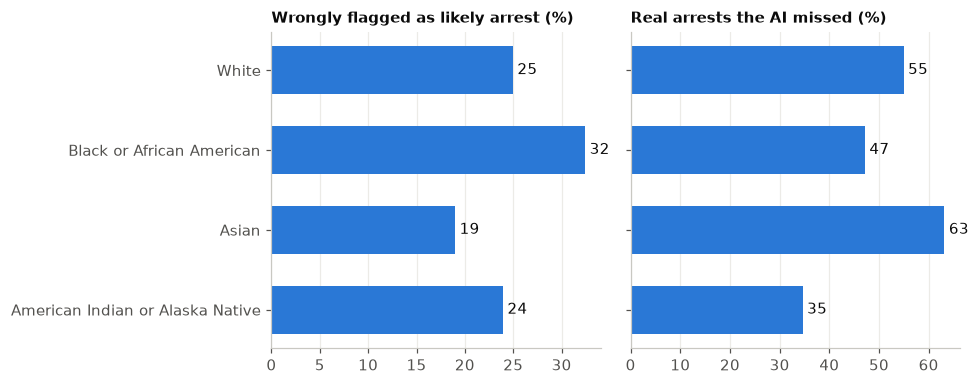

,stops,actual arrest %,AI average chance %,flagged likely %,wrongly flagged %,missed arrests %,AUC
White,3181.0,18.8,18.3,28.7,25.0,54.9,0.629
Black or African American,2309.0,19.7,19.5,36.5,32.4,47.1,0.633
Unknown,931.0,13.3,18.7,32.4,29.1,46.0,0.691
Asian,254.0,15.0,17.1,21.7,19.0,63.2,0.598
American Indian or Alaska Native,143.0,18.2,18.8,31.5,23.9,34.6,0.699


In [13]:
def summarise_group(actual_outcomes, chances, level):
    """Work out the fairness numbers for one group of stops."""
    said_likely = chances >= level
    is_arrest_stop = actual_outcomes == 1
    return {"stops": len(actual_outcomes),
            "actual arrest %": is_arrest_stop.mean() * 100,
            "AI average chance %": chances.mean() * 100,
            "flagged likely %": said_likely.mean() * 100,
            "wrongly flagged %": said_likely[~is_arrest_stop].mean() * 100,
            "missed arrests %": (~said_likely[is_arrest_stop]).mean() * 100,
            "AUC": roc_auc_score(actual_outcomes, chances)}


def build_fairness_table(exam_table, chances, level):
    """Compare the AI's results across every perceived race group that has enough exam stops."""
    outcomes = exam_table["ended_in_arrest"].to_numpy()
    groups = exam_table["perceived_race"].to_numpy()
    summaries = {group: summarise_group(outcomes[groups == group], chances[groups == group], level)
                 for group in pd.unique(groups) if (groups == group).sum() >= MINIMUM_GROUP_SIZE}
    return pd.DataFrame(summaries).T.sort_values("stops", ascending=False)


# Build the table. The chart leaves out stops where race was not recorded.
fairness_table = build_fairness_table(exam_stops, exam_chances, alert_level)
charted_groups = fairness_table[~fairness_table.index.isin(UNRECORDED_RACE_LABELS)]

# Draw wrongly flagged and missed arrests side by side, with one axis per measure.
figure, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for axis, column, title in [(axes[0], "wrongly flagged %", "Wrongly flagged as likely arrest (%)"),
                            (axes[1], "missed arrests %", "Real arrests the AI missed (%)")]:
    bars = axis.barh(charted_groups.index, charted_groups[column], color=BLUE, height=0.6)
    axis.bar_label(bars, fmt="%.0f", padding=3)
    axis.set_title(title, fontsize=10)
    axis.grid(axis="y", visible=False)
axes[0].invert_yaxis()
save_chart(figure, "04_fairness_by_perceived_race.png")
plt.show()
fairness_table.round({"stops": 0, "actual arrest %": 1, "AI average chance %": 1, "flagged likely %": 1,
                      "wrongly flagged %": 1, "missed arrests %": 1, "AUC": 3})

In [14]:
def weighted_share(is_counted, row_weights):
    """Work out a percentage when some stops were drawn more than once."""
    return 100 * row_weights[is_counted].sum() / row_weights.sum()


def compare_two_groups_once(tables, row_weights):
    """Work out the gap between two groups in one round: first group minus second group."""
    first, second = tables
    gaps = {}
    for measure, wanted_outcome, wanted_call in [("wrongly flagged", 0, True), ("missed arrests", 1, False)]:
        shares = [weighted_share(table["said_likely"][table["outcome"] == wanted_outcome] == wanted_call,
                                 row_weights[table["rows"]][table["outcome"] == wanted_outcome])
                  for table in (first, second)]
        gaps[measure] = shares[0] - shares[1]
    return gaps


def describe_group(exam_table, chances, level, group):
    """Collect one group's row positions, real outcomes and AI calls."""
    rows = np.flatnonzero(exam_table["perceived_race"].to_numpy() == group)
    return {"rows": rows, "outcome": exam_table["ended_in_arrest"].to_numpy()[rows], "said_likely": chances[rows] >= level}


def bootstrap_group_gaps(exam_table, chances, level, groups):
    """Measure the gap between two groups, plus the range it could move by chance."""
    tables = [describe_group(exam_table, chances, level, group) for group in groups]
    actual_gaps = compare_two_groups_once(tables, np.ones(len(exam_table)))
    rounds = [compare_two_groups_once(tables, row_weights) for row_weights in draw_random_incident_weights(exam_table)]
    ranges = pd.DataFrame(rounds).quantile([0.025, 0.975]).T.set_axis(["range low", "range high"], axis=1)
    return pd.Series(actual_gaps, name="gap (percentage points)").to_frame().join(ranges)


# Compare the two largest groups. If a range does not include 0, the gap is unlikely to be chance alone.
fairness_gaps = bootstrap_group_gaps(exam_stops, exam_chances, alert_level, [BLACK_PERCEIVED_RACE, "White"])
print("Black or African American minus White:")
fairness_gaps.round(1)

Black or African American minus White:


,gap (percentage points),range low,range high
wrongly flagged,7.5,4.7,10.6
missed arrests,-7.8,-14.3,-1.6


## Step 9: Save the AI

We save the taught AI to a file, along with its details, so it can be used without teaching it again.

In [15]:
def collect_known_values(stops_to_read):
    """Record every value the AI has seen, so a typing mistake can be caught later."""
    return {feature: sorted(stops_to_read[feature].unique().tolist()) for feature in CALL_FEATURES + PLACE_FEATURES}


# Write down everything needed to understand and use the saved model.
model_details = {
    "model": best_model_name,
    "taught_on": f"{FIRST_RELIABLE_YEAR}-{LAST_TRAINING_YEAR}",
    "stops_taught_on": len(teaching_stops),
    "chance_adjustment_from_2024": chance_adjustment,
    "data_fingerprint": data_fingerprint,
    "features": ALL_FEATURES,
    "alert_level": alert_level,
    "arrest_rate_2024": float(choosing_stops["ended_in_arrest"].mean()),
    "exam_scores_2025_2026": {name: round(float(score), 4) for name, score in exam_scores.items()},
    "yardstick_scores_2025_2026": {name: round(float(score), 4) for name, score in yardstick_scores.items()},
    "known_values": collect_known_values(teaching_stops),
    "limits": "Learning project. Seattle data only. Predicts officer decisions, not guilt. Not for use on real people.",
}

# Save the model and its details as two files.
joblib.dump(best_model, MODEL_PATH)
MODEL_DETAILS_PATH.write_text(json.dumps(model_details, indent=2))
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1_000:.0f} KB) and {MODEL_DETAILS_PATH}")

Saved models/arrest_outcome_model.joblib (14 KB) and models/arrest_outcome_model_details.json


## Step 10: Run the AI

We load the AI back from its file, as a separate program would, then give it example stops.

To try your own, change the examples or add one. The call details must match wording from the data, otherwise you get
an error telling you which detail is wrong.

In [16]:
def load_saved_ai():
    """Load the taught model and its details from their files."""
    return joblib.load(MODEL_PATH), json.loads(MODEL_DETAILS_PATH.read_text())


def check_stop_details(stop, known_values):
    """Stop with a clear message if a detail is one the AI has never seen."""
    for feature, allowed_values in known_values.items():
        if stop[feature] not in allowed_values:
            raise ValueError(f"'{feature}' cannot be '{stop[feature]}'. Check the wording in the details file.")


def predict_arrest_chance(stop, model, details):
    """Return the AI's chance of arrest, from 0 to 1, for one described stop."""
    check_stop_details(stop, details["known_values"])
    stop_row = pd.DataFrame([stop])
    stop_row = add_time_features(stop_row, pd.to_datetime(stop_row["occurred_at"]))
    uncorrected_chance = model.predict_proba(stop_row[details["features"]])[:, 1]
    return float(shift_chances(uncorrected_chance, details["chance_adjustment_from_2024"])[0])


def describe_prediction(chance, details):
    """Put a chance into words, using the alert level chosen on the 2024 stops."""
    return "likely arrest" if chance >= details["alert_level"] else "arrest unlikely"


def run_examples(examples, model, details):
    """Run the AI on each example and return the results as a table."""
    rows = []
    for stop in examples:
        chance = predict_arrest_chance(stop, model, details)
        rows.append({"call": stop["initial_call_type"], "how received": stop["call_type"], "beat": stop["beat"],
                     "when": stop["occurred_at"], "chance %": round(chance * 100, 1),
                     "AI says": describe_prediction(chance, details)})
    return pd.DataFrame(rows)


# Load the AI from its file and check it gives the same answers as the model in memory.
saved_model, saved_details = load_saved_ai()
reloaded_chances = shift_chances(arrest_chances(saved_model, exam_stops), saved_details["chance_adjustment_from_2024"])
assert np.allclose(reloaded_chances, exam_chances), "The saved model gives different answers"

# Made-up example stops. The last two differ only in the beat, to show the effect of location alone.
example_stops = [
    {"call_type": "911", "initial_call_type": "WARRANT - FELONY PICKUP", "precinct": "West", "sector": "K", "beat": "K3",
     "occurred_at": "2026-11-04 14:30"},
    {"call_type": "911", "initial_call_type": "ASLT - DV CRITICAL", "precinct": "North", "sector": "N", "beat": "N3",
     "occurred_at": "2026-11-07 23:10"},
    {"call_type": "911", "initial_call_type": "SHOPLIFT - THEFT", "precinct": "West", "sector": "M", "beat": "M3",
     "occurred_at": "2026-11-05 16:00"},
    {"call_type": "ONVIEW", "initial_call_type": "PREMISE CHECK, OFFICER INITIATED ONVIEW ONLY", "precinct": "East",
     "sector": "E", "beat": "E2", "occurred_at": "2026-11-03 02:15"},
    {"call_type": "911", "initial_call_type": "SUSPICIOUS PERSON, VEHICLE, OR INCIDENT", "precinct": "West", "sector": "K",
     "beat": "K3", "occurred_at": "2026-11-06 11:00"},
    {"call_type": "911", "initial_call_type": "SUSPICIOUS PERSON, VEHICLE, OR INCIDENT", "precinct": "North", "sector": "N",
     "beat": "N3", "occurred_at": "2026-11-06 11:00"},
]

pd.set_option("display.max_colwidth", 60)
run_examples(example_stops, saved_model, saved_details)

,call,how received,beat,when,chance %,AI says
0,WARRANT - FELONY PICKUP,911,K3,2026-11-04 14:30,48.2,likely arrest
1,ASLT - DV CRITICAL,911,N3,2026-11-07 23:10,36.6,likely arrest
2,SHOPLIFT - THEFT,911,M3,2026-11-05 16:00,27.4,likely arrest
3,"PREMISE CHECK, OFFICER INITIATED ONVIEW ONLY",ONVIEW,E2,2026-11-03 02:15,16.8,arrest unlikely
4,"SUSPICIOUS PERSON, VEHICLE, OR INCIDENT",911,K3,2026-11-06 11:00,14.8,arrest unlikely
5,"SUSPICIOUS PERSON, VEHICLE, OR INCIDENT",911,N3,2026-11-06 11:00,14.1,arrest unlikely


In [17]:
# Check that a typing mistake gives a clear error instead of a made-up answer.
misspelled_stop = dict(example_stops[0], initial_call_type="WARRANT PICKUP WITH A TYPO")
try:
    predict_arrest_chance(misspelled_stop, saved_model, saved_details)
    raise AssertionError("The AI should have refused a call type it has never seen")
except ValueError as error:
    print("Refused correctly:", error)

Refused correctly: 'initial_call_type' cannot be 'WARRANT PICKUP WITH A TYPO'. Check the wording in the details file.


## What we found

**The AI learned something real, but it is weak.** On the 6,889 final exam stops from 2025-2026:

| Score | The AI | Range by chance | Yardstick |
|---|---|---|---|
| AUC (0.50 is a coin toss) | 0.637 | 0.620 to 0.654 | 0.500 |
| Average precision (higher is better) | 0.296 | 0.274 to 0.322 | 0.182 |
| Brier (lower is better) | 0.142 | 0.137 to 0.148 | 0.149 |

- **Its calls are often wrong.** When it said "likely arrest", it was right 28.1% of the time, and it caught 48.9% of real arrests.
- **Its percentages are close.** After the correction, it predicted 18.7% on average and the real rate was 18.2%.
- **The simple model won.** Gradient boosting didn't beat logistic regression, so the extra complexity added nothing here.
- **The call type does most of the work.** Location and time add very little. What decides most arrests probably happens during the stop, and the AI can't see that.

**It is not equally wrong for everyone.** Comparing people perceived as Black with people perceived as white:

- Their real arrest rates were close: 19.7% and 18.8%.
- Among stops with no arrest, the AI wrongly flagged 32.4% and 25.0%. That is a gap of 7.5 points (range 4.7 to 10.6).
- It also missed fewer real arrests for people perceived as Black: 47.1% and 54.9%. That is a gap of 7.8 points (range 1.6 to 14.3).
- The AI never saw race, yet the allowed details can partly reveal it (AUC 0.635).

This shows the gap exists, not why. Other groups are too small for firm comparisons.

**Limits to keep in mind:**
- It learned what officers decided, which is not the same as guilt or what should have happened.
- It only knows recorded Terry stops that have call details, in Seattle. It would not carry over to Jamaica or the JCF.
- Arrest rates keep changing. Its 2024 AUC of 0.680 fell to 0.637 in the exam, and the percentage correction will go out of date.

**How the exam was handled:** the first run showed the percentages were too high, so the correction was added and the exam was run again. The correction's value came only from 2024 and the model choice didn't change, but the idea did come from seeing that first exam result. The AUC went from 0.643 to 0.637 between the two runs, because the final model no longer includes 2024 in its teaching data.